# Partie 6 — Analyse critique : explicabilité (Grad-CAM) et analyse d'erreurs

**DiagnoCulture — diagnostic des maladies de la tomate** · notebook `06_explicabilite_gradcam`

Les parties précédentes ont mesuré *combien* le modèle est précis. Ici on cherche à comprendre **comment** il décide et **où il se trompe** — l'énoncé le demande (explicabilité + analyse d'au moins 10 erreurs). On travaille sur notre **meilleur classifieur** : le MobileNetV2 fine-tuné complet (`mbv2_full`, F1-macro 0,992 au test de la Partie 2).

> **Notebook autonome.** Il se lit et s'exécute **de haut en bas en une passe**. Il ne dépend pas du notebook `02_` : il recharge les poids `tl_mbv2_full_best.pt` depuis Drive, donc **aucun réentraînement**.

## Pourquoi Grad-CAM ?

Un réseau est une « boîte noire » : il sort une classe sans dire sur quoi il s'est appuyé. **Grad-CAM** produit une **carte de chaleur** superposée à l'image, qui montre les zones ayant le plus pesé dans la décision (rouge = forte influence). Le principe :

1. on prend la **dernière couche convolutive**, car ses cartes de features gardent encore une correspondance avec les **positions** dans l'image ;
2. on calcule le **gradient** du score de la classe prédite par rapport à ces cartes → il mesure l'importance de chaque carte ;
3. on fait la **somme pondérée** des cartes par ces gradients, un ReLU, puis on ré-agrandit à la taille de l'image.

## Ce qu'on veut vérifier

Les images de PlantVillage sont prises en **laboratoire sur fond uniforme**. Le risque signalé dans l'énoncé est le **shortcut learning** : le modèle pourrait « tricher » en apprenant le **fond** plutôt que les symptômes. Grad-CAM permet de trancher :

- rouge sur la **lésion / les taches** → le modèle regarde le bon endroit, prédiction fiable ;
- rouge sur le **fond ou les bords** → shortcut learning, risque d'effondrement sur une vraie photo de champ.

## 1. Mise en place (autonome) et rechargement du meilleur classifieur

On redéfinit tout ce qui est nécessaire (données, constantes, architecture) et on recharge les poids du MobileNetV2 complet.

In [1]:
# === 1a. Setup autonome ===
import kagglehub
import os, torch, torch.nn as nn
import pandas as pd
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

ROOT    = "/content/drive/MyDrive/Project_clean"
DATA    = os.path.join(ROOT, "data")       # split.csv
MODELS  = os.path.join(ROOT, "models")     # modèle P2
RESULTS = os.path.join(ROOT, "results")    # figures .png
for d in (DATA, MODELS, RESULTS): os.makedirs(d, exist_ok=True)

DATA_ROOT = os.path.join(kagglehub.dataset_download("emmarex/plantdisease"), "PlantVillage")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG = 160
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

clean_data = pd.read_csv(os.path.join(DATA, "split.csv"))          # path,label,class_idx,split
classes = (clean_data.drop_duplicates("class_idx").sort_values("class_idx")["label"]
           .str.replace("Tomato_", "", regex=False).tolist())
print("classes:", len(classes), "| device:", device)

Mounted at /content/drive
Using Colab cache for faster access to the 'plantdisease' dataset.
classes: 10 | device: cuda


In [2]:
# === 1b. Recharger le meilleur classifieur (MobileNetV2 complet, 10 classes) ===
def build_mobilenet_v2(num_classes=10):
    m = models.mobilenet_v2(weights=None)                          # pas besoin des poids ImageNet : on recharge les notres
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    return m

clf = build_mobilenet_v2(num_classes=10)
clf.load_state_dict(torch.load(os.path.join(MODELS, "tl_mbv2_full_best.pt"), map_location=device))
clf.to(device).eval()
print("MobileNetV2 complet recharge.")

MobileNetV2 complet recharge.


## 2. La fonction Grad-CAM

On accroche la **dernière couche conv** de MobileNetV2 (`features[-1]`, sortie 1280×5×5). Un *forward hook* récupère ses cartes de features, un *backward hook* récupère les gradients de la classe prédite. La moyenne spatiale des gradients donne le poids de chaque carte ; la somme pondérée + ReLU donne la zone qui a poussé la décision.

In [3]:
# === 2. Grad-CAM sur la derniere couche conv ===
import torch.nn.functional as F

target_layer = clf.features[-1]        # dernier bloc conv (sortie 1280 x 5 x 5)
_feats, _grads = {}, {}
target_layer.register_forward_hook(lambda m, i, o: _feats.__setitem__("v", o.detach()))
target_layer.register_full_backward_hook(lambda m, gi, go: _grads.__setitem__("v", go[0].detach()))

def gradcam(x, class_idx=None):
    # x : (1,3,160,160) normalise ImageNet
    clf.zero_grad()
    out = clf(x)                                   # forward -> remplit _feats
    if class_idx is None:
        class_idx = out.argmax(1).item()           # classe predite
    out[0, class_idx].backward()                   # backward -> remplit _grads
    fmap = _feats["v"][0]                           # cartes de features (1280,5,5)
    grad = _grads["v"][0]                           # gradients       (1280,5,5)
    w    = grad.mean(dim=(1, 2))                    # poids = importance de chaque carte
    cam  = F.relu((w[:, None, None] * fmap).sum(0)) # combinaison ponderee + ReLU
    cam  = cam / (cam.max() + 1e-8)                 # -> [0,1]
    cam  = F.interpolate(cam[None, None], size=(IMG, IMG), mode="bilinear", align_corners=False)[0, 0]
    return cam.cpu().numpy(), class_idx

## 3. Grad-CAM sur des prédictions correctes ET incorrectes

On prédit d'abord sur tout le jeu de test pour repérer les images bien classées et mal classées, puis on affiche, pour 4 de chaque : en haut l'image, en bas la carte Grad-CAM superposée.

corrects: 2379 | erreurs: 21


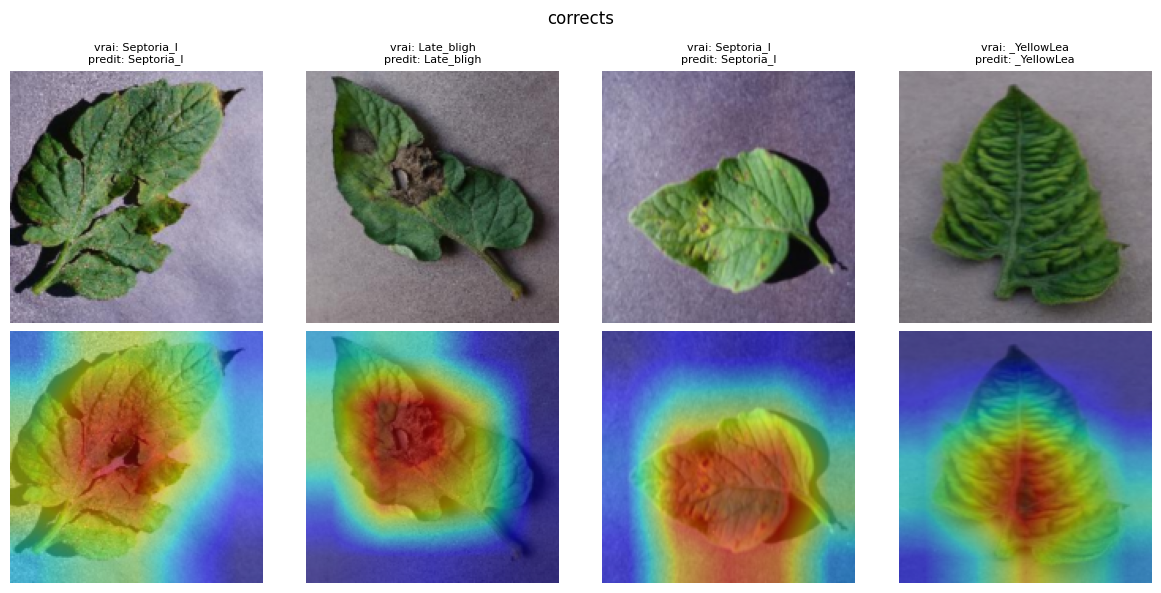

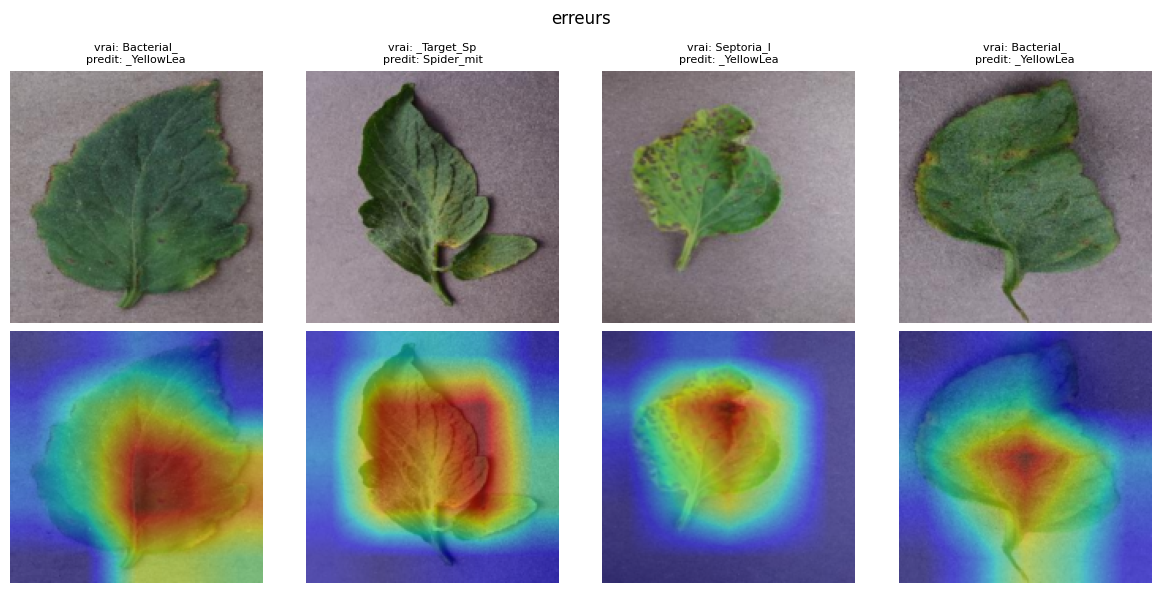

In [4]:
# === 3. Grad-CAM sur corrects vs erreurs ===
to_tensor = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor()])
normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

def load_one(path):
    img = Image.open(os.path.join(DATA_ROOT, path)).convert("RGB")
    raw = to_tensor(img)                                   # [0,1] pour l'affichage
    return normalize(raw).unsqueeze(0).to(device), raw.permute(1, 2, 0).numpy()

# predictions sur tout le test (pour reperer corrects / erreurs)
test_df = clean_data[clean_data.split == "test"].reset_index(drop=True).copy()
ps = []
with torch.no_grad():
    for i in range(0, len(test_df), 64):
        paths = test_df["path"].iloc[i:i+64]
        xs = torch.stack([normalize(to_tensor(Image.open(os.path.join(DATA_ROOT, p)).convert("RGB"))) for p in paths]).to(device)
        ps += clf(xs).argmax(1).cpu().tolist()
test_df["pred"] = ps
corrects = test_df[test_df.pred == test_df.class_idx]
errors   = test_df[test_df.pred != test_df.class_idx]
print("corrects:", len(corrects), "| erreurs:", len(errors))

def show_gradcam(rows, titre):
    n = len(rows)
    fig, ax = plt.subplots(2, n, figsize=(3*n, 6))
    for j, (_, r) in enumerate(rows.iterrows()):
        x, raw = load_one(r["path"])
        cam, pred = gradcam(x)
        ax[0, j].imshow(raw); ax[0, j].axis("off")
        ax[0, j].set_title(f"vrai: {classes[r['class_idx']][:10]}\npredit: {classes[pred][:10]}", fontsize=8)
        ax[1, j].imshow(raw); ax[1, j].imshow(cam, cmap="jet", alpha=0.5); ax[1, j].axis("off")
    fig.suptitle(titre); plt.tight_layout()
    plt.savefig(os.path.join(RESULTS, f"gradcam_{titre}.png"), dpi=120, bbox_inches="tight"); plt.show()

show_gradcam(corrects.sample(4, random_state=42), "corrects")
show_gradcam(errors.sample(4,   random_state=42), "erreurs")

### Interprétation Grad-CAM

**Le modèle ne s'appuie pas sur le fond.** Sur les prédictions correctes comme sur les erreurs, le fond uniforme est systématiquement en bleu (ignoré) ; la chaleur est toujours sur la feuille. Contrairement au risque de *shortcut learning* redouté avec PlantVillage, le MobileNetV2 n'utilise donc pas le fond de laboratoire pour décider.

**Quand il réussit, il regarde le bon endroit.** La chaleur se concentre sur la zone pertinente : la lésion nécrotique brune pour *Late_blight*, la surface mouchetée pour *Septoria*, la structure centrale recroquevillée pour *YellowLeaf_Curl*. Le modèle localise donc le symptôme lorsqu'il est **étendu, contrasté ou global**.

**Quand il échoue, le symptôme est petit et local.** Sur les erreurs, l'attention reste sur la feuille mais devient **diffuse et centrale**, et rate les petites taches diagnostiques situées sur les bords (ex. *Bacterial_spot*). Le modèle s'appuie alors sur l'apparence globale de la feuille plutôt que sur les lésions fines.

**Conclusion.** Le risque principal de ce prototype n'est donc pas le fond (bien écarté), mais une **dépendance à l'apparence globale** au détriment des **symptômes locaux discrets** — la même limite que celle observée pour l'auto-encodeur (P3/P4) et le VAE (P5). Sur une photo de champ, il garderait probablement sa force sur les maladies à symptômes étendus, mais resterait fragile sur les taches fines, en plus du changement de fond et d'éclairage.

## 4. Analyse d'erreurs : quelles familles d'erreurs ?

On affiche une grille d'images mal classées (vrai → prédit) et on compte les **confusions les plus fréquentes**.

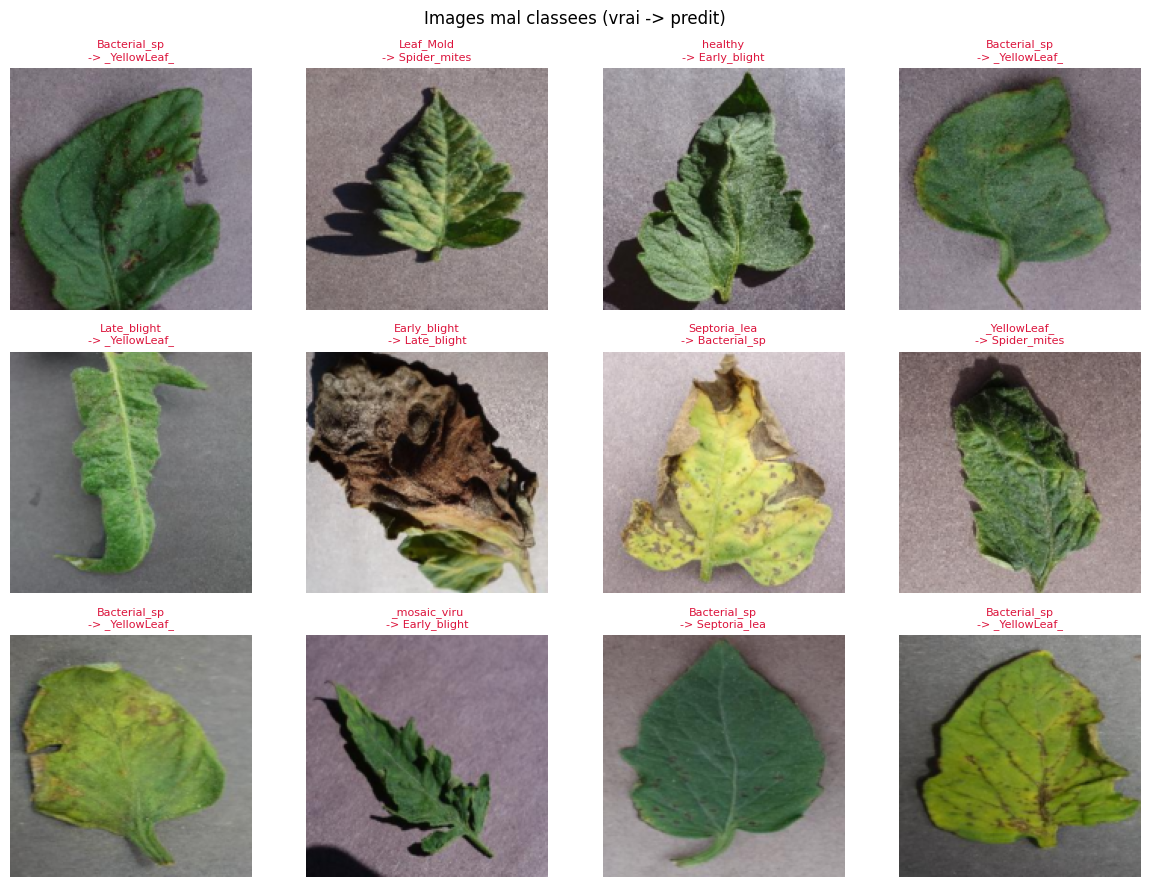

Confusions les plus frequentes (vrai -> predit) :
vrai                                  pred_n                              
Bacterial_spot                        _YellowLeaf__Curl_Virus                 8
                                      Septoria_leaf_spot                      1
Early_blight                          Bacterial_spot                          1
                                      Late_blight                             1
Late_blight                           Early_blight                            1
                                      _YellowLeaf__Curl_Virus                 1
Leaf_Mold                             Spider_mites_Two_spotted_spider_mite    1
Septoria_leaf_spot                    Bacterial_spot                          1
                                      _YellowLeaf__Curl_Virus                 1
Spider_mites_Two_spotted_spider_mite  _Target_Spot                            1
_Target_Spot                          Spider_mites_Two_spotted_spider_mite 

In [6]:
# === 4. Grille d'images mal classees (vrai -> predit) + confusions frequentes ===
sub = errors.sample(min(12, len(errors)), random_state=0).reset_index(drop=True)
R, C = 3, 4
fig, ax = plt.subplots(R, C, figsize=(12, 9))
for k in range(R*C):
    a = ax[k//C, k%C]; a.axis("off")
    if k < len(sub):
        r = sub.iloc[k]
        _, raw = load_one(r["path"])
        a.imshow(raw)
        a.set_title(f"{classes[r['class_idx']][:12]}\n-> {classes[r['pred']][:12]}", fontsize=8, color="crimson")
fig.suptitle("Images mal classees (vrai -> predit)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "gradcam_erreurs_grille.png"), dpi=120, bbox_inches="tight"); plt.show()

# les 10 confusions les plus frequentes
conf = (errors.assign(vrai=errors.class_idx.map(lambda i: classes[i]),
                      pred_n=errors.pred.map(lambda i: classes[i]))
              .groupby(["vrai", "pred_n"]).size().sort_values(ascending=False).head(25))
print("Confusions les plus frequentes (vrai -> predit) :")
print(conf)

### Analyse des erreurs

Le modèle ne commet que **21 erreurs sur 2400 images de test** (accuracy ≈ 99,1 %). Elles se regroupent ainsi :

- **Une confusion systématique domine : `Bacterial_spot → YellowLeaf_Curl` (8 cas, ~38 % des erreurs).** Les petites taches brunes de Bacterial_spot, souvent sur les bords, sont manquées (cf. Grad-CAM : attention diffuse au centre) ; quand la feuille jaunit, le modèle se rabat sur YellowLeaf_Curl — la **classe majoritaire** (3209 images). Au total, **10 des 21 erreurs** (≈ 48 %) prédisent YellowLeaf_Curl : nette **manifestation du déséquilibre** (en cas de doute, la classe dominante l'emporte). Cette confusion est déjà apparue en Partie 2, elle est donc **reproductible et systématique**.

- **Confusions entre maladies visuellement proches (1 cas chacune).** `Early_blight ↔ Late_blight` (taches brunes nécrotiques, dans les deux sens), `Spider_mites ↔ Target_Spot` (petites piqûres peu contrastées, dans les deux sens), `Leaf_Mold → Spider_mites` et `YellowLeaf_Curl → Spider_mites`, `Septoria → Bacterial_spot`, `Early_blight → Bacterial_spot`, `Septoria → YellowLeaf_Curl` : symptômes trop ressemblants à la résolution 160×160.

- **Classe minoritaire et faux positif.** `mosaic_virus → Early_blight` (1 cas) touche l'une des plus petites classes (56 images de test), difficile à apprendre. Et un cas **`healthy → Early_blight`** : un **faux positif** (feuille saine déclarée malade) — important pour la discussion éthique (traitement inutile déclenché).

**Lien avec le reste du projet :** les erreurs se concentrent sur des symptômes **petits, locaux ou peu contrastés** (Bacterial_spot, Spider_mites, Target_Spot) — exactement les maladies les moins bien détectées par l'auto-encodeur en Partie 3. Ces 21 erreurs sont noyées dans l'accuracy globale mais ressortent sur le **F1-macro** et le **rappel par classe**, d'où leur usage systématique dans ce projet.